# Uplift rankings on the test sample

X-learner is the pre-specified primary model; T-learner and response rankings are benchmarks. Covariate imbalance between assignment groups makes these descriptive ranking comparisons. Paired row bootstrap reselects the top-k users and holds fitted models fixed; it does not account for selection bias in the release.

Results are loaded from the saved analysis outputs.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
RESULTS = ROOT / 'results/full-run'
def table(name):
    frame = pd.read_csv(RESULTS / name)
    for column in frame.columns:
        if column == "two_sided_p_value":
            frame[column] = frame[column].map(lambda x: "< 1e-300" if x < 1e-300 else format(x, ".3g"))
        elif column.startswith("expected_loss_"):
            frame[column] = frame[column].map(lambda x: format(x, ".3e"))
    display(frame)
def figure(name):
    display(Image(filename=str(RESULTS / "figures" / name)))
def record(name):
    return json.loads((RESULTS / name).read_text())


,model,qini_coefficient,ci_lower,ci_upper
0,x_learner,0.090007,0.084828,0.095215
1,t_learner,0.087189,0.081585,0.092334
2,response,0.084187,0.078853,0.090846


,model,k,n_selected,n_treatment,n_control,visit_treatment,visit_control,incremental_visits_per_1000,gain_vs_random,ci_lower,ci_upper,random_per_1000,random_ci_lower,random_ci_upper,gain_ci_lower,gain_ci_upper
0,x_learner,0.1,419387,363404,55983,100790,12075,61.659249,51.316120,57.782205,65.462098,10.343129,9.806736,10.854852,47.972114,54.612098
1,x_learner,0.3,1258163,1075666,182497,139793,18376,29.267419,18.924290,27.740298,30.694198,10.343129,9.806736,10.854852,17.864797,20.025756
2,x_learner,0.5,2096939,1785400,311539,146751,19459,19.734147,9.391018,18.758196,20.627941,10.343129,9.806736,10.854852,8.912678,9.895898
3,t_learner,0.1,419387,363275,56112,102010,12343,60.835779,50.492650,57.288085,64.432688,10.343129,9.806736,10.854852,47.321714,53.716960
4,t_learner,0.3,1258163,1075470,182693,136509,17838,29.290413,18.947284,27.840718,30.899752,10.343129,9.806736,10.854852,17.857060,20.136402
5,t_learner,0.5,2096939,1785890,311049,141112,18576,19.294451,8.951322,18.371020,20.109803,10.343129,9.806736,10.854852,8.426099,9.445766
6,response,0.1,419387,361120,58267,135089,18813,51.207680,40.864551,47.566199,55.893760,10.343129,9.806736,10.854852,37.512178,44.906282
7,response,0.3,1258163,1074665,183498,166900,23206,28.839617,18.496489,27.274449,30.770561,10.343129,9.806736,10.854852,17.460698,19.850981
8,response,0.5,2096939,1784876,312063,171233,23795,19.684887,9.341758,18.665635,20.712278,10.343129,9.806736,10.854852,8.874043,9.949354


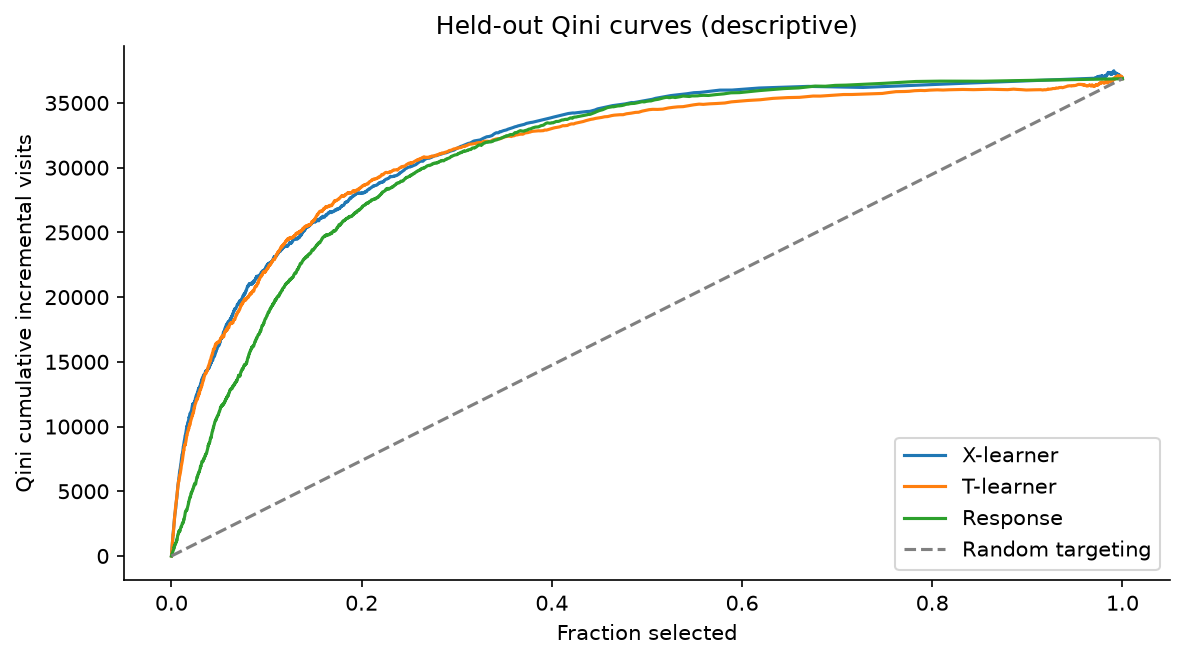

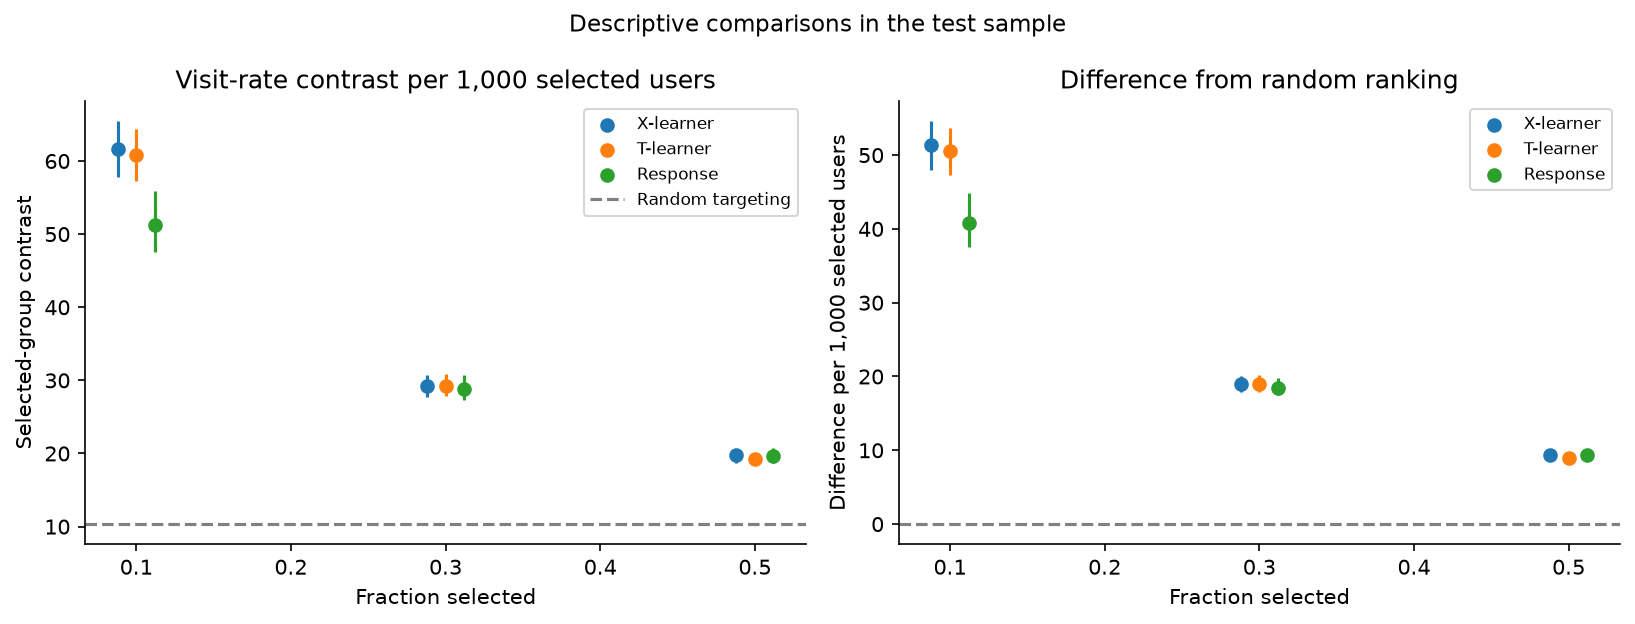

In [2]:
table("uplift_qini.csv")
table("uplift_targeting.csv")
figure("qini.png")
figure("targeting.png")

In [3]:
m = record("manifest.json")
display({k: m[k] for k in ["git", "data_sha256", "seeds", "hardware"]})

{'git': {'commit': '6928958aac539e9314c5d992203a826e9d1e5037',
  'source': 'local_repository',
  'working_tree_dirty': False,
  'release_source_matches': True},
 'data_sha256': '2716e1bf0fd157a93b5bf86924d9088419dfbac2022c6cd90030220634f616dc',
 'seeds': {'analysis': 2026,
  'simulation_root': 2026,
  'split': 2026,
  'lightgbm': 2026,
  'targeting_tie_break': 2026,
  'uplift_row_bootstrap': 2027},
 'hardware': {'os': 'macOS-26.6.2-arm64-arm-64bit',
  'architecture': 'arm64',
  'cpu': 'Apple M4',
  'physical_cores': 10,
  'logical_cores': 10,
  'ram_bytes': 17179869184,
  'python': '3.12.14'}}